# Phân tích cảm xúc bình luận Lazada

Project này xây dựng một baseline phân loại bình luận tiếng Việt thành `POS` và `NEG`. Notebook tập trung vào ba việc: kiểm tra chất lượng dữ liệu, xử lý các đặc thù tiếng Việt và so sánh những cấu hình mô hình đơn giản nhưng dễ giải thích.

**Kết quả trên split cố định (`random_state=42`)**

- TF-IDF + Logistic Regression đạt Accuracy khoảng **0,893**, Macro-F1 **0,862**.
- ROC-AUC khi xem `NEG` là lớp dương đạt khoảng **0,950**.
- Cân bằng trọng số giúp Recall của `NEG` tăng lên khoảng **0,904**, đổi lại Precision giảm.

Các con số dưới đây là kết quả holdout của project, không được hiểu như hiệu năng production.

## 1. Thiết lập và nạp dữ liệu

In [1]:
from pathlib import Path
from collections import Counter
import re
import sys
import unicodedata
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display, Markdown
from matplotlib import font_manager
from underthesea import word_tokenize
from wordcloud import WordCloud

from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    log_loss,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split


def find_project_root(start=Path.cwd()):
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "src").is_dir():
            return candidate
    raise FileNotFoundError("Không tìm thấy project root chứa pyproject.toml và src/.")


PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "lazada_data.csv"
RESOURCE_DIR = PROJECT_ROOT / "resources" / "nlp"

if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from lazada_sentiment import TextProcessor, build_sentiment_pipeline

warnings.filterwarnings("ignore", category=ConvergenceWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 160)

RANDOM_STATE = 42
text_processor = TextProcessor(RESOURCE_DIR)

print(f"Project root: {PROJECT_ROOT}")
print(f"Data: {DATA_PATH.relative_to(PROJECT_ROOT)}")

Project root: Y:\Data Analyst\Data Science\Data Pre\Thi\Final_2\Final_2\lazada-vietnamese-sentiment
Data: data\raw\lazada_data.csv


In [2]:
df_raw = pd.read_csv(DATA_PATH)
display(df_raw.head())

,comment,label
0,Thất vọng về sản phẩm khi nhận được.,NEG
1,Mà cái nơ hơi nặng nhưng không sao 😂😂.,POS
2,"Da mềm, sản phẩm đẹp.",POS
3,Rất không đáng tiền Shop phục vụ rất kém.,NEG
4,"Banh đẹp, vì mình mua về trang trí nên thấy bóng vậy là đẹp, giá cả hợp lý.",POS


## 2. Khám phá và kiểm tra chất lượng dữ liệu

### 2.1. Missing, trùng lặp và nhãn mâu thuẫn

In [3]:
overview = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(2),
    "n_unique": df_raw.nunique(dropna=False),
})
display(overview)

duplicate_rows = int(df_raw.duplicated().sum())
duplicate_comments = int(df_raw.duplicated(subset="comment").sum())
label_counts_per_comment = df_raw.groupby("comment", dropna=False)["label"].nunique()
conflicting_comments = set(label_counts_per_comment[label_counts_per_comment > 1].index)

print(f"Dòng trùng hoàn toàn: {duplicate_rows:,}")
print(f"Nội dung bình luận bị lặp: {duplicate_comments:,}")
print(f"Nội dung có nhãn mâu thuẫn: {len(conflicting_comments):,}")

# Loại missing/nhãn ngoài phạm vi, loại toàn bộ nội dung có nhãn mâu thuẫn,
# rồi giữ một bản ghi cho mỗi nội dung để ngăn cùng một câu xuất hiện ở train và test.
df = df_raw.dropna(subset=["comment", "label"]).copy()
df["comment"] = df["comment"].astype(str).str.strip()
df["label"] = df["label"].astype(str).str.upper().str.strip()
df = df[df["comment"].ne("") & df["label"].isin(["POS", "NEG"])]
df = df[~df["comment"].isin(conflicting_comments)]
df = df.drop_duplicates(subset="comment").reset_index(drop=True)

print(f"Kích thước dùng cho phân tích/mô hình: {len(df):,} dòng")

,dtype,missing,missing_pct,n_unique
comment,object,0,0.0,12911
label,object,0,0.0,2


Dòng trùng hoàn toàn: 2,073
Nội dung bình luận bị lặp: 2,089
Nội dung có nhãn mâu thuẫn: 16
Kích thước dùng cho phân tích/mô hình: 12,895 dòng


### 2.2. Phân phối nhãn

,count,percent
label,,
POS,9326,72.32
NEG,3569,27.68


C:\Users\Admin\AppData\Local\Temp\ipykernel_5984\528375133.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="label", order=["NEG", "POS"], palette=["#D95F59", "#4C78A8"], ax=ax)


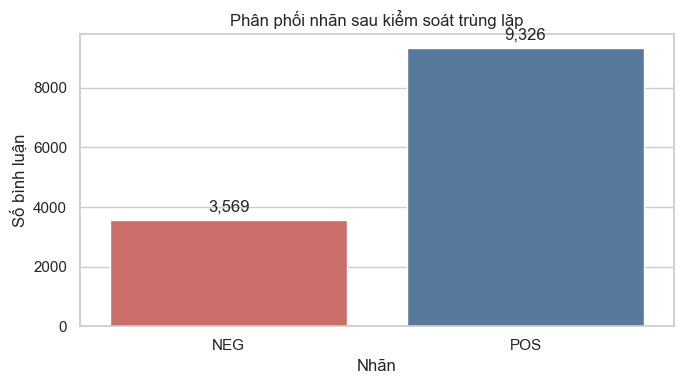

In [4]:
label_summary = df["label"].value_counts().rename("count").to_frame()
label_summary["percent"] = (label_summary["count"] / len(df) * 100).round(2)
display(label_summary)

majority_accuracy = label_summary["count"].max() / len(df)
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x="label", order=["NEG", "POS"], palette=["#D95F59", "#4C78A8"], ax=ax)
ax.set(title="Phân phối nhãn sau kiểm soát trùng lặp", xlabel="Nhãn", ylabel="Số bình luận")
for patch in ax.patches:
    ax.annotate(f"{int(patch.get_height()):,}", (patch.get_x() + patch.get_width()/2, patch.get_height()),
                ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")
plt.tight_layout()
plt.show()

Dữ liệu lệch về lớp POS (72,32%), vì vậy Accuracy đứng riêng lẻ sẽ khá dễ gây hiểu nhầm. Một mô hình đoán toàn bộ là POS vẫn đạt Accuracy 72,32% nhưng không phát hiện được bình luận tiêu cực nào. Phần đánh giá bên dưới vì thế đọc thêm Macro-F1 và các metric riêng của lớp NEG.

### 2.3. Từ thường gặp trong nhóm NEG

,Từ/cụm từ,Tần suất
0,không,1736
1,hàng,562
2,áo,546
3,shop,507
4,giao,485
5,màu,434
6,sản_phẩm,429
7,vải,339
8,kém,332
9,mua,321


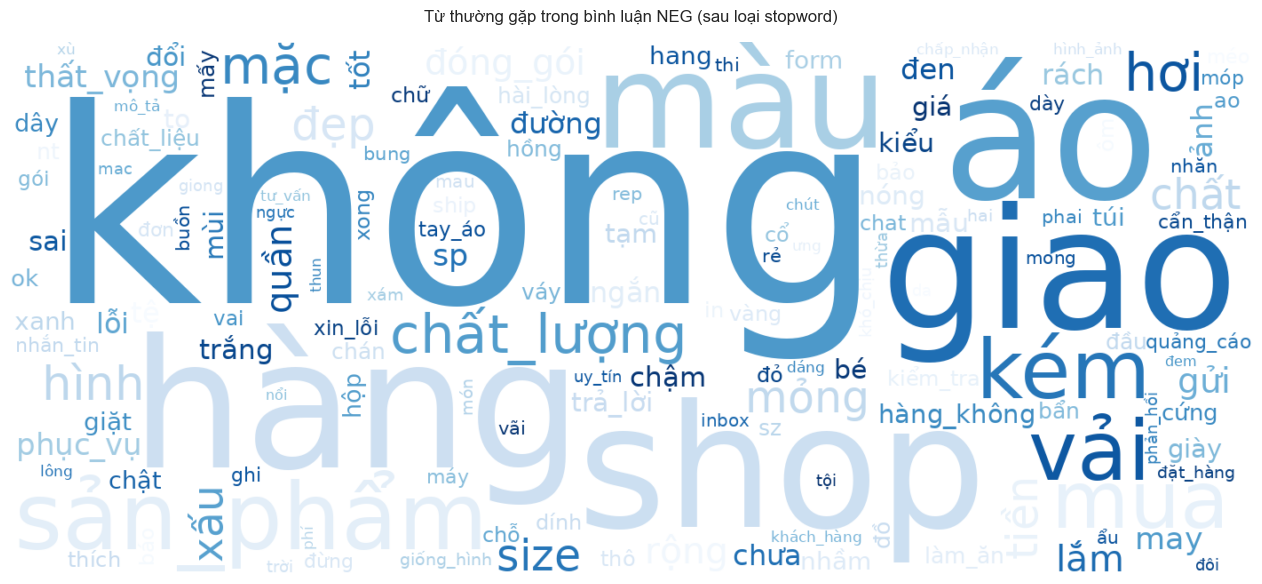


Mười từ/cụm từ đứng đầu là **không, hàng, áo, shop, giao, màu, sản_phẩm, vải, kém, mua**. Nhóm **hàng, áo, shop, màu, sản_phẩm, vải, chất_lượng, tiền** gợi ý rằng phản hồi tiêu cực thường nhắc tới sản phẩm thực nhận và trải nghiệm giao hàng.

Đây chỉ là thống kê tần suất. Những từ như `đẹp` vẫn có thể nằm trong câu phủ định hoặc một bình luận vừa khen vừa chê, nên WordCloud không được dùng như bằng chứng về nguyên nhân.


In [5]:
# WordCloud dùng cùng bộ teencode/stopword với pipeline chính.
wordcloud_teencode = text_processor.teencode_dict
wordcloud_stopwords = set(text_processor.stopwords)
wordcloud_stopwords.difference_update(text_processor.negators)


def tokenize_for_wordcloud(text):
    text = unicodedata.normalize("NFC", str(text).lower())
    text = re.sub(r"https?://\S+|www\.\S+|\S+@\S+", " ", text)
    text = re.sub(r"[^0-9A-Za-zÀ-ỹ_\s]", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = " ".join(wordcloud_teencode.get(token, token) for token in text.split())
    segmented = word_tokenize(text, format="text")
    return [
        token
        for token in segmented.split()
        if len(token) > 1 and token not in wordcloud_stopwords
    ]


negative_tokens = [
    token
    for comment in df.loc[df["label"].eq("NEG"), "comment"]
    for token in tokenize_for_wordcloud(comment)
]
negative_frequency = Counter(negative_tokens)
top_negative_words = pd.DataFrame(
    negative_frequency.most_common(20),
    columns=["Từ/cụm từ", "Tần suất"],
)
display(top_negative_words)

font_path = font_manager.findfont("DejaVu Sans")
negative_wordcloud = WordCloud(
    width=1400,
    height=600,
    background_color="white",
    colormap="Blues",
    max_words=150,
    collocations=False,
    font_path=font_path,
    random_state=RANDOM_STATE,
).generate_from_frequencies(negative_frequency)

plt.figure(figsize=(14, 6))
plt.imshow(negative_wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Từ thường gặp trong bình luận NEG (sau loại stopword)", pad=14)
plt.tight_layout()
plt.show()

top_10_terms = ", ".join(top_negative_words.head(10)["Từ/cụm từ"])
shopping_dimensions = {
    "sản_phẩm", "chất_lượng", "giao_hàng", "hàng", "áo", "vải",
    "màu", "size", "tiền", "giá", "shop", "đóng_gói",
}
visible_dimensions = [
    term for term in top_negative_words["Từ/cụm từ"]
    if term in shopping_dimensions
]
dimension_text = ", ".join(visible_dimensions[:8]) or "các thuộc tính sản phẩm và giao nhận"

display(Markdown(f"""
Mười từ/cụm từ đứng đầu là **{top_10_terms}**. Nhóm **{dimension_text}** gợi ý rằng phản hồi tiêu cực thường nhắc tới sản phẩm thực nhận và trải nghiệm giao hàng.

Đây chỉ là thống kê tần suất. Những từ như `đẹp` vẫn có thể nằm trong câu phủ định hoặc một bình luận vừa khen vừa chê, nên WordCloud không được dùng như bằng chứng về nguyên nhân.
"""))

### 2.4. Độ dài bình luận theo nhãn

char_count               word_count              avg_word_length         \
            mean median    std       mean median   std            mean median   
label                                                                           
NEG        43.87   34.0  35.93      10.25    8.0  8.25            4.26   4.25   
POS        50.77   37.0  43.16      11.45    8.0  9.51            4.40   4.39   

             
        std  
label        
NEG    0.48  
POS    0.58

C:\Users\Admin\AppData\Local\Temp\ipykernel_5984\3996762402.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df[df[column] <= upper], x="label", y=column,
C:\Users\Admin\AppData\Local\Temp\ipykernel_5984\3996762402.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df[df[column] <= upper], x="label", y=column,


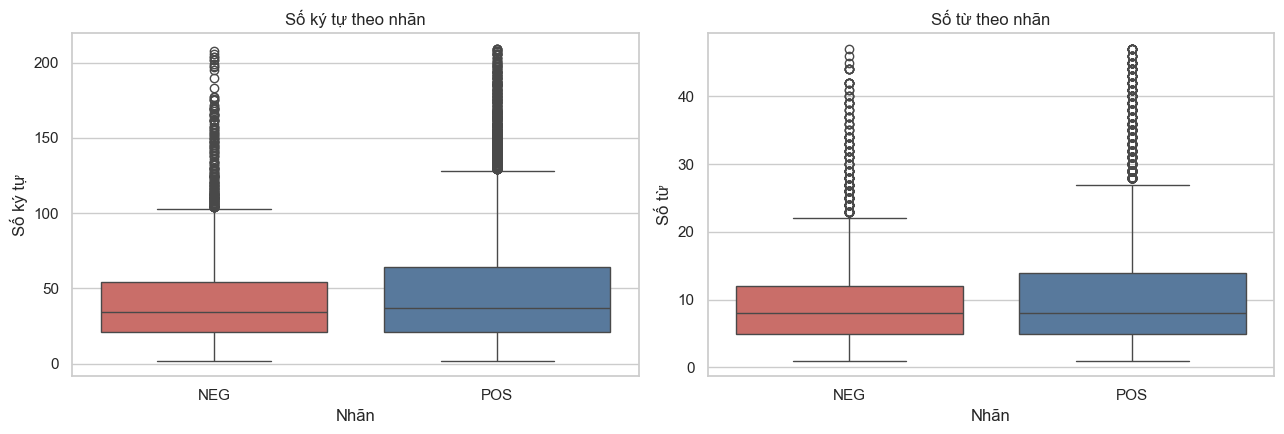

In [6]:
df["char_count"] = df["comment"].str.len()
df["word_count"] = df["comment"].str.split().str.len()
df["avg_word_length"] = (df["char_count"] / df["word_count"].replace(0, np.nan)).fillna(0)

length_summary = df.groupby("label")[["char_count", "word_count", "avg_word_length"]].agg(
    ["mean", "median", "std"]
).round(2)
display(length_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, column, title in zip(
    axes,
    ["char_count", "word_count"],
    ["Số ký tự", "Số từ"],
):
    upper = df[column].quantile(0.99)
    sns.boxplot(data=df[df[column] <= upper], x="label", y=column,
                order=["NEG", "POS"], palette=["#D95F59", "#4C78A8"], ax=ax)
    ax.set(title=f"{title} theo nhãn", xlabel="Nhãn", ylabel=title)
plt.tight_layout()
plt.show()

**Quan sát:** Trung vị của hai nhóm đều bằng 8 từ. Nhóm POS có mean word count 11,45 so với 10,25 ở NEG và mean char count 50,77 so với 43,87. Chênh lệch nằm nhiều ở phần đuôi phân phối, nên kết quả này chỉ cho thấy POS có xu hướng dài hơn nhẹ, chưa phải bằng chứng về khác biệt có ý nghĩa thống kê.

## 3. Tiền xử lý văn bản

Bộ xử lý đọc năm tài nguyên trong `resources/nlp/`: emoji, teencode, ánh xạ Anh–Việt, wrong-word và stopword. Cụm phủ định được bảo vệ trước khi lọc từ; danh từ cũng được giữ lại để mô hình biết đối tượng nào đang được khen hoặc chê.

In [7]:
resource_summary = pd.Series(
    text_processor.resource_summary(),
    name="Số mục đã nạp",
).to_frame()
display(resource_summary)

sample_comments = [
    "SP đẹp, ship nhanh 👍👍",
    "Ko đáng tiền, giao hàng chậm 😡",
    "Mình chưa hài lòng vì chất lượng không tốt",
]
display(pd.DataFrame({
    "original": sample_comments,
    "processed": [text_processor.transform(text) for text in sample_comments],
}))

,Số mục đã nạp
emoji,43
teencode,392
english_vietnamese,4177
wrong_words,11842
stopwords,1954


,original,processed
0,"SP đẹp, ship nhanh 👍👍",đẹp chóng thích thích
1,"Ko đáng tiền, giao hàng chậm 😡",không_đáng tiền hàng chậm giận_dữ
2,Mình chưa hài lòng vì chất lượng không tốt,chưa_hài_lòng chất_lượng không_tốt


### 3.1. Làm sạch toàn bộ dữ liệu

In [8]:
df["clean_text"] = df["comment"].map(text_processor.transform)
empty_clean = int(df["clean_text"].eq("").sum())
print(f"Số văn bản rỗng sau tiền xử lý: {empty_clean:,}")

df_model = df[df["clean_text"].ne("")].copy().reset_index(drop=True)
display(df_model[["comment", "clean_text", "label"]].sample(8, random_state=RANDOM_STATE))
print(f"Kích thước sẵn sàng mô hình hóa: {len(df_model):,} dòng")

Số văn bản rỗng sau tiền xử lý: 184


,comment,clean_text,label
12140,Rộng b ạ . chất đẹp.,rộng chất đẹp,POS
9689,Đóng gói sản phẩm chưa được thẩm mĩ còn xấu.,đóng_gói sản_phẩm chưa_được thẩm_mĩ xấu,NEG
2910,Còn có thư cảm ơn rất dễ thương nữa ^^.,thư dễ_thương,POS
304,Áo mỏng hơn so với áo màu vàng.,áo mỏng áo màu vàng,POS
7936,"Sản phẩm không như mong đợi, lớp da mỏng nên dáng túi k theo khuôn khổ nào cả.",sản_phẩm không_như_đợi lớp mỏng dáng túi không_theo khuôn_khổ,NEG
4081,Chất lượng sản phẩm rất kém Thời gian giao hàng rất chậm Shop phục vụ rất kém.,chất_lượng sản_phẩm kém thời hàng chậm cửa tiệm phục_vụ kém,NEG
12545,Đẹp nhưng from hơi rộng,đẹp hơi rộng,POS
10178,Thái độ rất kém.,thái_độ kém,NEG


Kích thước sẵn sàng mô hình hóa: 12,711 dòng


### Vì sao pipeline xử lý theo cách này?

- Emoji và teencode mang tín hiệu cảm xúc trực tiếp, nên project chuẩn hóa bằng toàn bộ dictionary thay vì một danh sách ví dụ ngắn.
- POS-tagging giữ tính từ, động từ, trạng từ và danh từ. Chỉ giữ từ biểu cảm sẽ làm mất đối tượng đang được đánh giá như `giao_hàng` hoặc `chất_lượng`.
- Phủ định được ghép sớm (`không_tốt`, `chưa_hài_lòng`) để stopword/POS filter không làm rơi mất tín hiệu.

## 4. Vector hóa và huấn luyện

In [9]:
X = df_model["clean_text"]
y = df_model["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

split_summary = pd.DataFrame({
    "train_count": y_train.value_counts(),
    "train_pct": (y_train.value_counts(normalize=True) * 100).round(2),
    "test_count": y_test.value_counts(),
    "test_pct": (y_test.value_counts(normalize=True) * 100).round(2),
}).fillna(0).astype({"train_count": int, "test_count": int})
display(split_summary)
print(f"Train: {len(X_train):,} | Test: {len(X_test):,}")

,train_count,train_pct,test_count,test_pct
label,,,,
POS,7343,72.22,1837,72.24
NEG,2825,27.78,706,27.76


Train: 10,168 | Test: 2,543


In [10]:
model_specs = {
    "Count | Không cân bằng": ("count", None),
    "Count | balanced": ("count", "balanced"),
    "TF-IDF | Không cân bằng": ("tfidf", None),
    "TF-IDF | balanced": ("tfidf", "balanced"),
}
models = {
    name: build_sentiment_pipeline(kind, weight, RANDOM_STATE)
    for name, (kind, weight) in model_specs.items()
}

predictions = {}
probabilities = {}
evaluation_rows = []

for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba_pos = model.predict_proba(X_test)[:, list(model.classes_).index("POS")]
    predictions[model_name] = y_pred
    probabilities[model_name] = y_proba_pos

    report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    evaluation_rows.append({
        "model": model_name,
        "vectorizer": "TF-IDF" if model_name.startswith("TF-IDF") else "Count",
        "imbalance": "balanced" if model_name.endswith("balanced") else "none",
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_f1": report["macro avg"]["f1-score"],
        "NEG_precision": report["NEG"]["precision"],
        "NEG_recall": report["NEG"]["recall"],
        "NEG_f1": report["NEG"]["f1-score"],
        "POS_precision": report["POS"]["precision"],
        "POS_recall": report["POS"]["recall"],
        "POS_f1": report["POS"]["f1-score"],
    })

evaluation_df = pd.DataFrame(evaluation_rows).set_index("model")
metric_columns = [
    column for column in evaluation_df.columns
    if column not in ["vectorizer", "imbalance"]
]
display(
    evaluation_df.style
    .format({column: "{:.3f}" for column in metric_columns})
    .highlight_max(subset=metric_columns, axis=0, color="#d8f3dc")
)

vectorizer_summary = evaluation_df.groupby("vectorizer")[["accuracy", "macro_f1"]].max()
best_vectorizer = vectorizer_summary["macro_f1"].idxmax()
display(vectorizer_summary.round(3))
display(Markdown(
    f"Theo Macro-F1 tốt nhất trong bốn cấu hình, **{best_vectorizer}** phù hợp hơn "
    "trên split hiện tại. Kết luận này là thực nghiệm, không phải giả định từ lý thuyết."
))

,vectorizer,imbalance,accuracy,macro_f1,NEG_precision,NEG_recall,NEG_f1,POS_precision,POS_recall,POS_f1
model,,,,,,,,,,
Count | Không cân bằng,Count,none,0.888,0.858,0.820,0.766,0.792,0.912,0.935,0.924
Count | balanced,Count,balanced,0.875,0.854,0.722,0.892,0.798,0.955,0.868,0.909
TF-IDF | Không cân bằng,TF-IDF,none,0.892,0.862,0.838,0.759,0.796,0.911,0.943,0.927
TF-IDF | balanced,TF-IDF,balanced,0.874,0.853,0.716,0.904,0.799,0.959,0.862,0.908


,accuracy,macro_f1
vectorizer,,
Count,0.888,0.858
TF-IDF,0.892,0.862


Theo Macro-F1 tốt nhất trong bốn cấu hình, **TF-IDF** phù hợp hơn trên split hiện tại. Kết luận này là thực nghiệm, không phải giả định từ lý thuyết.

### Lựa chọn mô hình

CountVectorizer và TF-IDF được so sánh trên cùng một split. `Pipeline` đảm bảo vectorizer chỉ học vocabulary/IDF từ tập train. `class_weight="balanced"` cũng chỉ tác động trong quá trình fit, không thay đổi tập test.

Với use case phát hiện phản hồi xấu, metric của NEG quan trọng hơn Accuracy tổng thể. Phần đánh giá giữ cả hai cấu hình để thấy rõ sự đánh đổi giữa bỏ sót và báo động nhầm.

## 5. Đánh giá mô hình

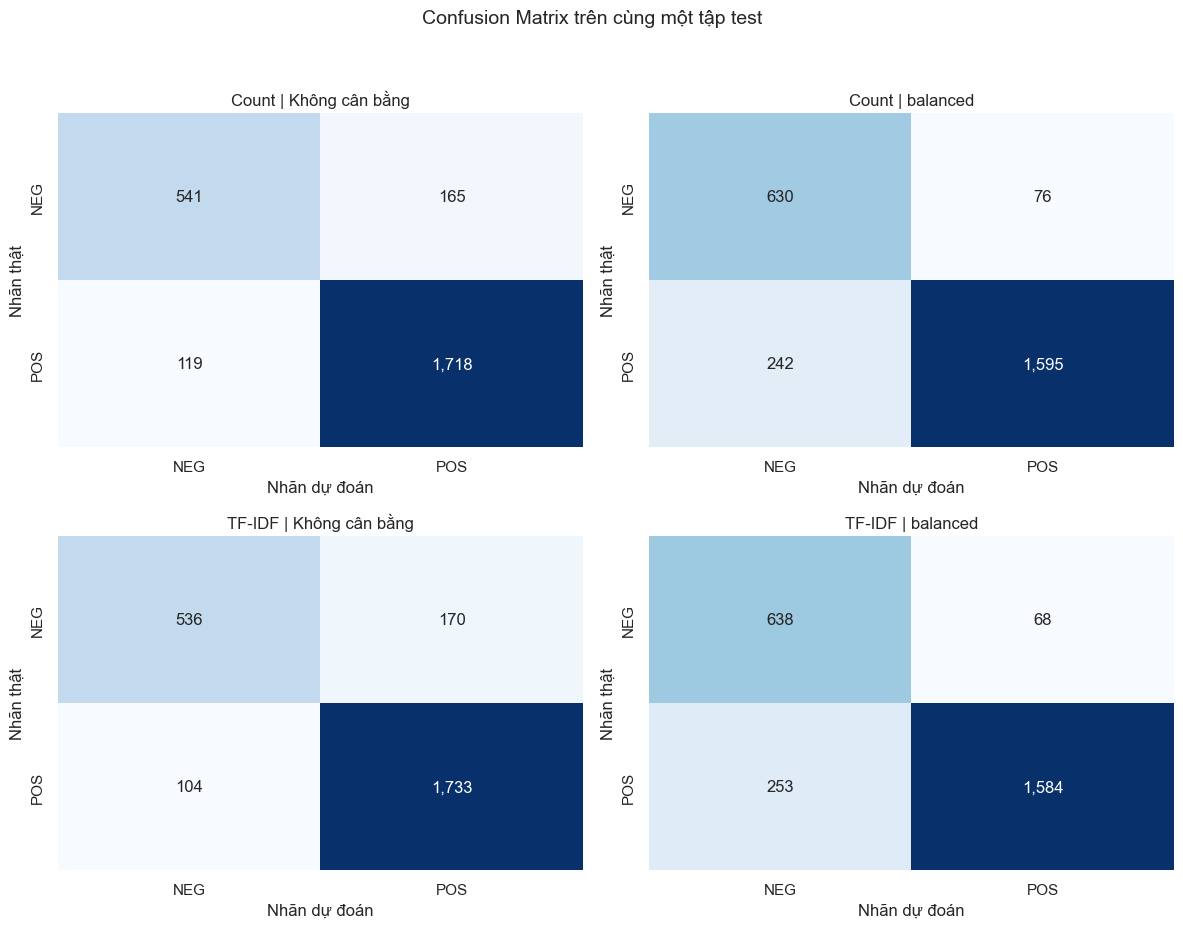

Count | Không cân bằng
Accuracy: 0.8883
              precision    recall  f1-score   support

         NEG     0.8197    0.7663    0.7921       706
         POS     0.9124    0.9352    0.9237      1837

    accuracy                         0.8883      2543
   macro avg     0.8660    0.8508    0.8579      2543
weighted avg     0.8866    0.8883    0.8871      2543

Count | balanced
Accuracy: 0.8750
              precision    recall  f1-score   support

         NEG     0.7225    0.8924    0.7985       706
         POS     0.9545    0.8683    0.9094      1837

    accuracy                         0.8750      2543
   macro avg     0.8385    0.8803    0.8539      2543
weighted avg     0.8901    0.8750    0.8786      2543

TF-IDF | Không cân bằng
Accuracy: 0.8923
              precision    recall  f1-score   support

         NEG     0.8375    0.7592    0.7964       706
         POS     0.9107    0.9434    0.9267      1837

    accuracy                         0.8923      2543
   macro avg 

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (model_name, y_pred) in zip(axes.ravel(), predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=["NEG", "POS"])
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
                xticklabels=["NEG", "POS"], yticklabels=["NEG", "POS"], ax=ax)
    ax.set(title=model_name, xlabel="Nhãn dự đoán", ylabel="Nhãn thật")
plt.suptitle("Confusion Matrix trên cùng một tập test", y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

for model_name, y_pred in predictions.items():
    print("=" * 80)
    print(model_name)
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(classification_report(y_test, y_pred, labels=["NEG", "POS"], digits=4, zero_division=0))

In [12]:
baseline = evaluation_df.loc["TF-IDF | Không cân bằng", metric_columns]
balanced = evaluation_df.loc["TF-IDF | balanced", metric_columns]
comparison = pd.DataFrame({
    "Thay đổi (balanced - baseline)": balanced - baseline
}).T
display(comparison.style.format("{:+.3f}"))

display(Markdown(
    f"**So sánh trên cùng TF-IDF:** `class_weight='balanced'` làm NEG Recall thay đổi "
    f"**{balanced['NEG_recall'] - baseline['NEG_recall']:+.3f}**, NEG F1 "
    f"**{balanced['NEG_f1'] - baseline['NEG_f1']:+.3f}**, và Accuracy "
    f"**{balanced['accuracy'] - baseline['accuracy']:+.3f}** so với baseline. "
    "Đây là trade-off cần cân nhắc theo chi phí bỏ sót bình luận tiêu cực."
))

,accuracy,macro_f1,NEG_precision,NEG_recall,NEG_f1,POS_precision,POS_recall,POS_f1
Thay đổi (balanced - baseline),-0.018,-0.008,-0.121,+0.144,+0.003,+0.048,-0.081,-0.019


**So sánh trên cùng TF-IDF:** `class_weight='balanced'` làm NEG Recall thay đổi **+0.144**, NEG F1 **+0.003**, và Accuracy **-0.018** so với baseline. Đây là trade-off cần cân nhắc theo chi phí bỏ sót bình luận tiêu cực.

### 5.1. ROC-AUC cho lớp NEG

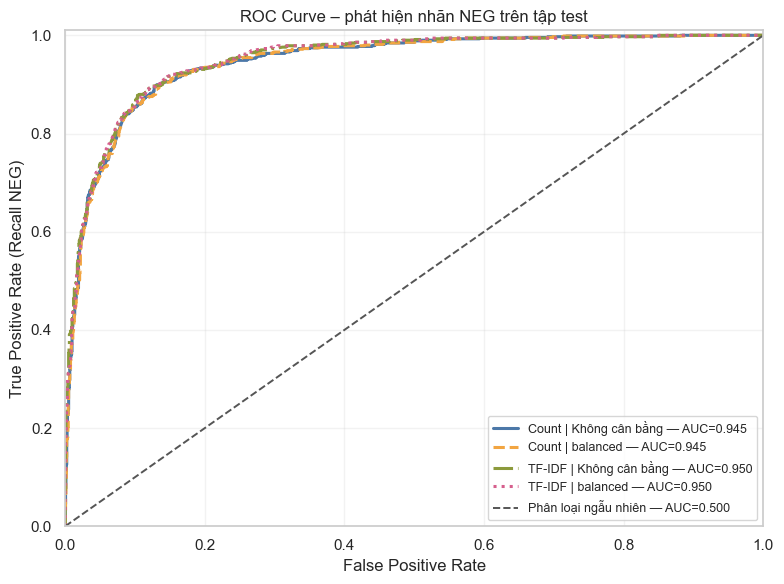

,ROC–AUC
TF-IDF | Không cân bằng,0.950
TF-IDF | balanced,0.950
Count | Không cân bằng,0.945
Count | balanced,0.945


**Nhận xét ROC:** **TF-IDF | Không cân bằng** có ROC–AUC cao nhất (**0.950**) khi xem NEG là lớp cần phát hiện. ROC–AUC đo khả năng xếp hạng trên mọi ngưỡng; với dữ liệu mất cân bằng, vẫn cần đọc cùng Recall, Precision và F1 của NEG.

In [13]:
# Đánh giá ROC cho nhãn NEG trên cùng một tập test.
y_test_neg = y_test.eq("NEG").astype(int)

roc_colors = {
    "Count | Không cân bằng": "#4C78A8",
    "Count | balanced": "#F2A541",
    "TF-IDF | Không cân bằng": "#8C9A3C",
    "TF-IDF | balanced": "#D65F8D",
}
roc_line_styles = {
    "Count | Không cân bằng": "-",
    "Count | balanced": "--",
    "TF-IDF | Không cân bằng": "-.",
    "TF-IDF | balanced": ":",
}

roc_auc_results = {}
fig, ax = plt.subplots(figsize=(8, 6))

for model_name, probability_pos in probabilities.items():
    probability_neg = 1 - probability_pos
    false_positive_rate, true_positive_rate, _ = roc_curve(
        y_test_neg,
        probability_neg,
    )
    auc_value = roc_auc_score(y_test_neg, probability_neg)
    roc_auc_results[model_name] = auc_value
    ax.plot(
        false_positive_rate,
        true_positive_rate,
        color=roc_colors[model_name],
        linestyle=roc_line_styles[model_name],
        linewidth=2.2,
        label=f"{model_name} — AUC={auc_value:.3f}",
    )

ax.plot([0, 1], [0, 1], color="#555555", linestyle="--", linewidth=1.4,
        label="Phân loại ngẫu nhiên — AUC=0.500")
ax.set(
    title="ROC Curve – phát hiện nhãn NEG trên tập test",
    xlabel="False Positive Rate",
    ylabel="True Positive Rate (Recall NEG)",
    xlim=(0, 1),
    ylim=(0, 1.01),
)
ax.legend(loc="lower right", frameon=True, fontsize=9)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

roc_auc_df = pd.Series(roc_auc_results, name="ROC–AUC").sort_values(ascending=False).to_frame()
display(roc_auc_df.style.format("{:.3f}").highlight_max(color="#d8f3dc"))

best_roc_model = roc_auc_df.index[0]
display(Markdown(
    f"**Nhận xét ROC:** **{best_roc_model}** có ROC–AUC cao nhất "
    f"(**{roc_auc_results[best_roc_model]:.3f}**) khi xem NEG là lớp cần phát hiện. "
    "ROC–AUC đo khả năng xếp hạng trên mọi ngưỡng; với dữ liệu mất cân bằng, vẫn cần đọc cùng Recall, Precision và F1 của NEG."
))

### 5.2. Cross-Entropy Log Loss

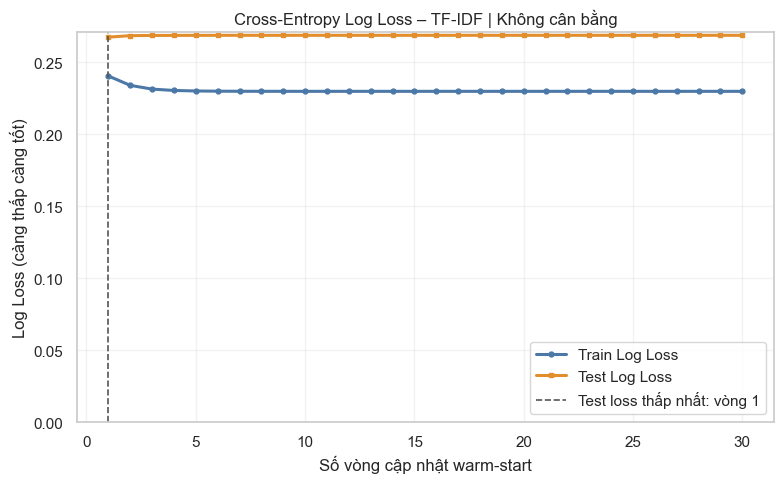

,Vòng lặp,Train Log Loss,Test Log Loss
0,1,0.2405,0.2675
1,2,0.2340,0.2686
2,3,0.2314,0.2687
27,28,0.2299,0.2688
28,29,0.2299,0.2688
29,30,0.2299,0.2688


**Nhận xét Loss:** Test Log Loss thấp nhất là **0.2675** tại vòng **1**. Trong kết quả này, train loss giảm từ 0.2405 xuống 0.2299, nhưng test loss tăng từ 0.2675 lên 0.2688; đây là dấu hiệu overfitting nhẹ sau các vòng đầu.

In [14]:
# Chọn cấu hình tốt nhất theo Macro-F1 và tái sử dụng vectorizer đã fit trên train.
loss_model_name = evaluation_df["macro_f1"].idxmax()
selected_pipeline = models[loss_model_name]
selected_vectorizer = selected_pipeline.named_steps["vectorizer"]
selected_class_weight = selected_pipeline.named_steps["logreg"].class_weight

X_train_loss = selected_vectorizer.transform(X_train)
X_test_loss = selected_vectorizer.transform(X_test)

# Warm-start giúp vòng sau tiếp tục từ hệ số của vòng trước.
diagnostic_logreg = LogisticRegression(
    solver="saga",
    max_iter=1,
    warm_start=True,
    tol=1e-8,
    class_weight=selected_class_weight,
    random_state=RANDOM_STATE,
)

loss_history = []
number_of_rounds = 30

for training_round in range(1, number_of_rounds + 1):
    diagnostic_logreg.fit(X_train_loss, y_train)
    train_probability = diagnostic_logreg.predict_proba(X_train_loss)
    test_probability = diagnostic_logreg.predict_proba(X_test_loss)

    loss_history.append({
        "Vòng lặp": training_round,
        "Train Log Loss": log_loss(
            y_train,
            train_probability,
            labels=diagnostic_logreg.classes_,
        ),
        "Test Log Loss": log_loss(
            y_test,
            test_probability,
            labels=diagnostic_logreg.classes_,
        ),
    })

loss_history_df = pd.DataFrame(loss_history)
best_loss_row = loss_history_df.loc[loss_history_df["Test Log Loss"].idxmin()]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    loss_history_df["Vòng lặp"],
    loss_history_df["Train Log Loss"],
    color="#4C78A8",
    linewidth=2.2,
    marker="o",
    markersize=3.5,
    label="Train Log Loss",
)
ax.plot(
    loss_history_df["Vòng lặp"],
    loss_history_df["Test Log Loss"],
    color="#E28E2C",
    linewidth=2.2,
    marker="s",
    markersize=3.5,
    label="Test Log Loss",
)
ax.axvline(
    best_loss_row["Vòng lặp"],
    color="#555555",
    linestyle="--",
    linewidth=1.2,
    label=f"Test loss thấp nhất: vòng {int(best_loss_row['Vòng lặp'])}",
)
ax.set(
    title=f"Cross-Entropy Log Loss – {loss_model_name}",
    xlabel="Số vòng cập nhật warm-start",
    ylabel="Log Loss (càng thấp càng tốt)",
)
ax.set_ylim(bottom=0)
ax.legend(frameon=True)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

loss_preview = pd.concat([
    loss_history_df.head(3),
    loss_history_df.tail(3),
]).drop_duplicates()
display(loss_preview.style.format({
    "Train Log Loss": "{:.4f}",
    "Test Log Loss": "{:.4f}",
}))

first_loss_row = loss_history_df.iloc[0]
last_loss_row = loss_history_df.iloc[-1]
if (
    last_loss_row["Train Log Loss"] < first_loss_row["Train Log Loss"]
    and last_loss_row["Test Log Loss"] > best_loss_row["Test Log Loss"] + 1e-4
):
    loss_interpretation = (
        f"Trong kết quả này, train loss giảm từ {first_loss_row['Train Log Loss']:.4f} "
        f"xuống {last_loss_row['Train Log Loss']:.4f}, nhưng test loss tăng từ "
        f"{best_loss_row['Test Log Loss']:.4f} lên {last_loss_row['Test Log Loss']:.4f}; "
        "đây là dấu hiệu overfitting nhẹ sau các vòng đầu."
    )
else:
    loss_interpretation = (
        "Train và test loss chưa phân kỳ rõ; chưa thấy dấu hiệu overfitting đáng kể "
        "trong số vòng đã chạy."
    )

display(Markdown(
    f"**Nhận xét Loss:** Test Log Loss thấp nhất là "
    f"**{best_loss_row['Test Log Loss']:.4f}** tại vòng "
    f"**{int(best_loss_row['Vòng lặp'])}**. {loss_interpretation}"
))

## 6. Kết quả và phân tích lỗi

### 6.1. Những dự đoán sai đáng xem lại

In [15]:
# Macro-F1 giúp hai lớp có trọng số ngang nhau khi chọn baseline tổng quát.
best_model_name = evaluation_df["macro_f1"].idxmax()
best_model = models[best_model_name]
best_pred = predictions[best_model_name]
best_pos_probability = probabilities[best_model_name]

test_results = df_model.loc[X_test.index, ["comment", "clean_text", "label"]].copy()
test_results["prediction"] = best_pred
test_results["P(POS)"] = best_pos_probability
test_results["correct"] = test_results["label"].eq(test_results["prediction"])

errors = test_results[~test_results["correct"]].copy()
errors["confidence"] = np.where(errors["prediction"].eq("POS"), errors["P(POS)"], 1 - errors["P(POS)"])

positive_hints = {"đẹp", "tốt", "thích", "tuyệt", "nhanh", "ổn", "yêu", "hài lòng"}
negative_hints = {"tệ", "kém", "xấu", "chậm", "thất vọng", "không", "chưa", "chẳng", "chả", "đừng", "khỏi", "ẩu", "lỗi"}
mixed_markers = {"nhưng", "mà", "tuy", "có điều", "dù"}

def infer_error_cause(row):
    raw = row["comment"].lower()
    has_positive = any(term in raw for term in positive_hints)
    has_negative = any(term in raw for term in negative_hints)
    if any(marker in raw for marker in mixed_markers) or (has_positive and has_negative):
        return "Cảm xúc hỗn hợp / nhiều khía cạnh"
    if row["label"] == "NEG" and row["prediction"] == "POS" and has_positive and not has_negative:
        return "Có khả năng nhiễu nhãn"
    raw_words = max(len(raw.split()), 1)
    if len(row["clean_text"].split()) / raw_words < 0.45:
        return "Có thể mất tín hiệu khi làm sạch/POS-tag"
    return "Ngữ cảnh ngắn, từ hiếm hoặc sắc thái khó"

errors["nguyên_nhân_khả_dĩ"] = errors.apply(infer_error_cause, axis=1)
error_examples = errors.sort_values("confidence", ascending=False).head(3)[
    ["comment", "clean_text", "label", "prediction", "P(POS)", "confidence", "nguyên_nhân_khả_dĩ"]
]
display(error_examples)

best_metrics = evaluation_df.loc[best_model_name]
best_class = "NEG" if best_metrics["NEG_f1"] > best_metrics["POS_f1"] else "POS"
weak_class = "POS" if best_class == "NEG" else "NEG"
train_distribution = y_train.value_counts(normalize=True)
operations_model_name = evaluation_df["NEG_recall"].idxmax()
operations_metrics = evaluation_df.loc[operations_model_name]

,comment,clean_text,label,prediction,P(POS),confidence,nguyên_nhân_khả_dĩ
8955,Tốt nhất lần sau khỏi mua.,tốt khỏi_mua,NEG,POS,0.990720,0.990720,Cảm xúc hỗn hợp / nhiều khía cạnh
9600,Ánh sáng tốt.,ánh_sáng tốt,NEG,POS,0.990720,0.990720,Có khả năng nhiễu nhãn
6035,"Giao hàng nhanh làm tốt, giày phù hợp với mức giá và khá tốt.",hàng chóng tốt giày giá tốt,NEG,POS,0.985166,0.985166,Có khả năng nhiễu nhãn


In [16]:
display(Markdown(f"""
## Kết luận

### Kết quả mô hình

- Mô hình được chọn theo **Macro-F1** là **{best_model_name}** với Accuracy **{best_metrics['accuracy']:.3f}** và Macro-F1 **{best_metrics['macro_f1']:.3f}**.
- NEG: Precision **{best_metrics['NEG_precision']:.3f}**, Recall **{best_metrics['NEG_recall']:.3f}**, F1 **{best_metrics['NEG_f1']:.3f}**.
- POS: Precision **{best_metrics['POS_precision']:.3f}**, Recall **{best_metrics['POS_recall']:.3f}**, F1 **{best_metrics['POS_f1']:.3f}**.
- Theo F1, mô hình nhận diện tốt hơn nhãn **{best_class}** và yếu hơn ở **{weak_class}**. Train có {train_distribution.get('POS', 0):.1%} POS và {train_distribution.get('NEG', 0):.1%} NEG;
lớp POS có nhiều ví dụ hơn, còn `class_weight='balanced'` giúp bù chi phí sai cho NEG.

### Ý nghĩa thực tiễn

Nếu hệ thống dùng để phát hiện bình luận xấu và chuyển cho CSKH, nên ưu tiên **Recall của NEG**:
bỏ sót một khách hàng không hài lòng (false negative) có thể khiến khiếu nại không được xử lý và làm tăng rủi ro
rời bỏ. Trong các cấu hình đã thử, **{operations_model_name}** có NEG Recall cao nhất (**{operations_metrics['NEG_recall']:.3f}**)
với NEG Precision **{operations_metrics['NEG_precision']:.3f}**.
Precision vẫn cần một ngưỡng tối thiểu để đội CSKH không bị quá tải.
Trong vận hành nên điều chỉnh ngưỡng xác suất theo năng lực xử lý, thay vì mặc định 0.5 cho mọi thời điểm.

### Phân tích lỗi điển hình

Bảng trên hiển thị có độ tự tin cao và gắn **nguyên nhân khả dĩ** cho từng mẫu.
Các nhóm chính là: nhãn gốc có dấu hiệu không khớp nội dung; một bình luận vừa khen vừa chê nhiều khía cạnh;
hoặc tín hiệu quan trọng bị suy giảm do từ hiếm/POS-tagging.
Đây là chẩn đoán định tính để định hướng rà soát, không phải khẳng định tự động rằng nhãn gốc chắc chắn sai.
Nên kiểm tra thủ công các mẫu này, bổ sung sửa lỗi chính tả và cân nhắc sentiment theo khía cạnh.

### Hạn chế và hướng phát triển

- WordCloud mô tả tần suất, không đo tác động hay quan hệ nhân quả.
- POS-tagging tổng quát có thể gán sai tag cho teencode và tên sản phẩm.
- Có thể đánh giá bằng cross-validation, tối ưu ngưỡng theo chi phí vận hành,
và so sánh với mô hình ngữ cảnh tiếng Việt như PhoBERT.
"""))


## Kết luận

### Kết quả mô hình

- Mô hình được chọn theo **Macro-F1** là **TF-IDF | Không cân bằng** với Accuracy **0.892** và Macro-F1 **0.862**.
- NEG: Precision **0.838**, Recall **0.759**, F1 **0.796**.
- POS: Precision **0.911**, Recall **0.943**, F1 **0.927**.
- Theo F1, mô hình nhận diện tốt hơn nhãn **POS** và yếu hơn ở **NEG**. Train có 72.2% POS và 27.8% NEG;
lớp POS có nhiều ví dụ hơn, còn `class_weight='balanced'` giúp bù chi phí sai cho NEG.

### Ý nghĩa thực tiễn

Nếu hệ thống dùng để phát hiện bình luận xấu và chuyển cho CSKH, nên ưu tiên **Recall của NEG**:
bỏ sót một khách hàng không hài lòng (false negative) có thể khiến khiếu nại không được xử lý và làm tăng rủi ro
rời bỏ. Trong các cấu hình đã thử, **TF-IDF | balanced** có NEG Recall cao nhất (**0.904**)
với NEG Precision **0.716**.
Precision vẫn cần một ngưỡng tối thiểu để đội CSKH không bị quá tải.
Trong vận hành nên điều chỉnh ngưỡng xác suất theo năng lực xử lý, thay vì mặc định 0.5 cho mọi thời điểm.

### Phân tích lỗi điển hình

Bảng trên hiển thị có độ tự tin cao và gắn **nguyên nhân khả dĩ** cho từng mẫu.
Các nhóm chính là: nhãn gốc có dấu hiệu không khớp nội dung; một bình luận vừa khen vừa chê nhiều khía cạnh;
hoặc tín hiệu quan trọng bị suy giảm do từ hiếm/POS-tagging.
Đây là chẩn đoán định tính để định hướng rà soát, không phải khẳng định tự động rằng nhãn gốc chắc chắn sai.
Nên kiểm tra thủ công các mẫu này, bổ sung sửa lỗi chính tả và cân nhắc sentiment theo khía cạnh.

### Hạn chế và hướng phát triển

- WordCloud mô tả tần suất, không đo tác động hay quan hệ nhân quả.
- POS-tagging tổng quát có thể gán sai tag cho teencode và tên sản phẩm.
- Có thể đánh giá bằng cross-validation, tối ưu ngưỡng theo chi phí vận hành,
và so sánh với mô hình ngữ cảnh tiếng Việt như PhoBERT.
